# AQI vs MODIS MOD13Q1 NDVI — pick the best NDVI variant

**Goal**: among `NDVI` (centre pixel), `NDVI_3x3_mean`, and `NDVI_5x5_mean`, decide which one correlates best with PM2.5 so it can be used as a model feature.

**Pairing — 16-day mean PM2.5 ↔ composite NDVI (avoids pseudoreplication)**:
MOD13Q1 NDVI is one value per 16-day window. To stay at the *same temporal scale*, we collapse hourly PM2.5 to its mean over each composite window `[composite_start_date, composite_start_date + 16d)`. Result: **1 paired row = 1 (station, composite)** — N ≈ 108 stations × ~100 composites ≈ 10⁴, not 10⁶.

This is a deliberate change from a first draft that paired hourly PM2.5 against the repeated composite NDVI; that inflated N and gave artificially small p-values without adding any independent information.

**Stations**: every Envisoft station present in both `AQI/process` and `MODIS_MOD13Q1/stations`.

Plots follow the reference RANSAC pattern from `EDA/AOD_Comparision/v2/aqi_aod/`: density-coloured scatter, OLS line, RANSAC line (inliers), metric box.

## 0. Setup

In [1]:
%matplotlib inline
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, RANSACRegressor

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

AQI_DIR     = Path('/home/slow_data/Air_Quality/AQI/process')
NDVI_DIR    = Path('/home/slow_data/Air_Quality/MODIS_MOD13Q1/stations')
STATION_MAP = Path('/home/work1/projects/Air_Quality/Masterdata/envisoft_station_map.csv')
FIG_DIR     = Path('/home/work1/projects/Air_Quality/pm25_map/ndvi/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

NDVI_WINDOWS = [
    ('center', 'NDVI'),
    ('3x3',    'NDVI_3x3_mean'),
    ('5x5',    'NDVI_5x5_mean'),
]
COMPOSITE_DAYS = pd.Timedelta('16D')
# Drop composites that have less than this many AQI hours in their 16d window.
# 24h = 1 full day out of 16; lower it for sparse stations, raise for stricter QA.
MIN_HOURS_PER_COMPOSITE = 24
COLUMNS = [c for _, c in NDVI_WINDOWS]
print(f'NDVI variants            : {[lbl for lbl, _ in NDVI_WINDOWS]}')
print(f'min AQI hours / composite: {MIN_HOURS_PER_COMPOSITE}')
print(f'figures dir              : {FIG_DIR}')

NDVI variants            : ['center', '3x3', '5x5']
min AQI hours / composite: 24
figures dir              : /home/work1/projects/Air_Quality/pm25_map/ndvi/figures


## 1. Helpers — file matching, loaders, 16-day aggregation pairing

`pair_aqi_ndvi` assigns each hourly AQI sample to the composite whose 16-day window contains it, then aggregates PM2.5 → (mean, median, n_hours) per composite, then joins with the composite's NDVI values. Composites with too few AQI hours are dropped via `MIN_HOURS_PER_COMPOSITE`.

In [2]:
_KEY_RE = re.compile(r'(?:[^\w]|_)+', flags=re.UNICODE)

def normalize_key(name: str) -> str:
    return _KEY_RE.sub('', str(name).lower())

def scan_folder(folder: Path) -> dict:
    return {normalize_key(p.stem): p for p in folder.glob('*.csv') if p.is_file()}

def load_aqi_hourly(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, usecols=['datetime', 'pm2.5'], low_memory=False)
    df = df.rename(columns={'pm2.5': 'pm25'})
    df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
    df['pm25']     = pd.to_numeric(df['pm25'], errors='coerce')
    return df.dropna(subset=['datetime', 'pm25']).sort_values('datetime')

def load_ndvi_composites(path: Path, columns) -> pd.DataFrame:
    df = pd.read_csv(path, usecols=['composite_start_date', *columns], low_memory=False)
    df['composite_start_date'] = pd.to_datetime(df['composite_start_date'], errors='coerce')
    for c in columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df.dropna(subset=['composite_start_date']).sort_values('composite_start_date')

def pair_aqi_ndvi(aqi: pd.DataFrame, ndvi: pd.DataFrame, columns,
                  min_hours: int = MIN_HOURS_PER_COMPOSITE) -> pd.DataFrame:
    """Aggregate hourly PM2.5 to the NDVI composite's 16-day window.

    Returns one row per (composite_start_date) with mean/median PM2.5 over
    [start, start+16d), hourly count, and the NDVI columns from that composite.
    Drops windows that overlap < `min_hours` AQI samples.
    """
    if aqi.empty or ndvi.empty:
        return pd.DataFrame()
    starts = np.sort(ndvi['composite_start_date'].to_numpy())
    # For each AQI hour, find the latest composite start ≤ its datetime.
    idx = np.searchsorted(starts, aqi['datetime'].to_numpy(), side='right') - 1
    valid = idx >= 0
    a = aqi.loc[valid].copy()
    a['composite_start_date'] = starts[idx[valid]]
    # Drop hours that fall past the composite's 16-day window (gap between composites).
    a = a[(a['datetime'] - a['composite_start_date']) < COMPOSITE_DAYS]
    if a.empty:
        return pd.DataFrame()
    agg = a.groupby('composite_start_date').agg(
        pm25=('pm25', 'mean'),
        pm25_median=('pm25', 'median'),
        pm25_n_hours=('pm25', 'size'),
    ).reset_index()
    agg = agg[agg['pm25_n_hours'] >= min_hours]
    return agg.merge(ndvi[['composite_start_date', *columns]],
                     on='composite_start_date', how='inner')

## 2. Metrics + density scatter (same pattern as the AOD notebooks)

In [3]:
def fit_ransac(x, y, seed=0):
    if len(x) < 3:
        return np.nan, np.nan, 0
    try:
        rs = RANSACRegressor(
            estimator=LinearRegression(),
            min_samples=max(2, int(0.2 * len(x))),
            residual_threshold=None,
            random_state=seed,
        ).fit(x.reshape(-1, 1), y)
        return (float(rs.estimator_.coef_[0]),
                float(rs.estimator_.intercept_),
                int(rs.inlier_mask_.sum()))
    except ValueError:
        return np.nan, np.nan, 0

def evaluate(x, y):
    n = len(x)
    if n < 2:
        return dict(N=n, R=np.nan, R_spearman=np.nan, RMSE=np.nan, MAE=np.nan,
                    slope=np.nan, intercept=np.nan,
                    slope_r=np.nan, intercept_r=np.nan, N_in=0)
    r, _  = stats.pearsonr(x, y)
    rs, _ = stats.spearmanr(x, y)
    ols = LinearRegression().fit(x.reshape(-1, 1), y)
    slope, intercept = float(ols.coef_[0]), float(ols.intercept_)
    pred = slope * x + intercept
    rmse = float(np.sqrt(np.mean((y - pred) ** 2)))
    mae  = float(np.mean(np.abs(y - pred)))
    slope_r, intercept_r, n_in = fit_ransac(x, y)
    return dict(N=n, R=float(r), R_spearman=float(rs),
                RMSE=rmse, MAE=mae,
                slope=slope, intercept=intercept,
                slope_r=slope_r, intercept_r=intercept_r, N_in=n_in)

def plot_scatter(ax, x, y, *, xlabel, ylabel='mean PM2.5 over 16d (µg/m³)',
                 title=None, density=True):
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    metrics = evaluate(x, y)
    if metrics['N'] == 0:
        ax.set_title(f'{title or xlabel} — empty'); return metrics
    xlo, xhi = np.quantile(x, [0.001, 0.99])
    ylo, yhi = np.quantile(y, [0.001, 0.99])
    mm = (x >= xlo) & (x <= xhi) & (y >= ylo) & (y <= yhi)
    xp, yp = x[mm], y[mm]
    if density and len(xp) >= 5:
        try:
            z = stats.gaussian_kde(np.vstack([xp, yp]))(np.vstack([xp, yp]))
            order = z.argsort()
            ax.scatter(xp[order], yp[order], c=z[order], s=10, cmap='turbo')
        except Exception:
            ax.scatter(xp, yp, s=10, alpha=0.5, color='steelblue')
    else:
        ax.scatter(xp, yp, s=10, alpha=0.5, color='steelblue')
    grid = np.linspace(xlo, xhi, 100)
    if np.isfinite(metrics['slope']):
        ax.plot(grid, metrics['slope']*grid + metrics['intercept'], 'b-', lw=1.4,
                label=f"OLS y={metrics['slope']:.1f}x+{metrics['intercept']:.1f}")
    if np.isfinite(metrics['slope_r']):
        ax.plot(grid, metrics['slope_r']*grid + metrics['intercept_r'], 'g-', lw=1.4,
                label=(f"RANSAC y={metrics['slope_r']:.1f}x+{metrics['intercept_r']:.1f} "
                       f"(N_in={metrics['N_in']:,})"))
    txt = (f"N = {metrics['N']:,}\n"
           f"R = {metrics['R']:+.3f}\n"
           f"ρ = {metrics['R_spearman']:+.3f}\n"
           f"RMSE = {metrics['RMSE']:.2f}\n"
           f"MAE  = {metrics['MAE']:.2f}")
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, va='top',
            fontsize=9, family='monospace',
            bbox=dict(facecolor='white', edgecolor='0.7', alpha=0.85))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
    if title: ax.set_title(title)
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.3)
    return metrics

def save_fig(name, fig=None, dpi=140):
    f = fig if fig is not None else plt.gcf()
    out = FIG_DIR / f'{name}.png'
    f.savefig(out, dpi=dpi, bbox_inches='tight')
    return out

## 3. Build the paired DataFrame — one row per (station, composite)

In [4]:
master = pd.read_csv(STATION_MAP)
master['_key'] = master['stationName'].map(normalize_key)
aqi_lut  = scan_folder(AQI_DIR)
ndvi_lut = scan_folder(NDVI_DIR)

frames = []
missing_aqi = missing_ndvi = 0
for _, srow in master.iterrows():
    key = srow['_key']
    aqi_path = aqi_lut.get(key)
    ndvi_path = ndvi_lut.get(key)
    if aqi_path is None:
        missing_aqi += 1; continue
    if ndvi_path is None:
        missing_ndvi += 1; continue
    try:
        aqi  = load_aqi_hourly(aqi_path)
        ndvi = load_ndvi_composites(ndvi_path, COLUMNS)
    except Exception as e:
        print(f'  skip {srow["stationName"]}: {e}'); continue
    paired = pair_aqi_ndvi(aqi, ndvi, COLUMNS)
    if paired.empty:
        continue
    paired['station'] = srow['stationName']
    paired['region']  = srow['region']
    paired['lat']     = float(srow['latitude'])
    paired['lon']     = float(srow['longitude'])
    frames.append(paired)

pairs = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print(f'matched stations    : {len(frames)}')
print(f'missing AQI         : {missing_aqi}')
print(f'missing NDVI        : {missing_ndvi}')
print(f'paired rows shape   : {pairs.shape}')
if not pairs.empty:
    print(f'composite date span : {pairs["composite_start_date"].min().date()} → {pairs["composite_start_date"].max().date()}')
    print(f'mean hours/composite: {pairs["pm25_n_hours"].mean():.1f}  (median {pairs["pm25_n_hours"].median():.0f})')

matched stations    : 94
missing AQI         : 29
missing NDVI        : 0
paired rows shape   : (3497, 11)
composite date span : 2020-01-01 → 2026-05-09
mean hours/composite: 314.0  (median 359)


### 3.a Composites per station
Each station now contributes ≤ ~100 composites (1 per 16-day window over the AQI history). Stations near the floor are short-history stations.

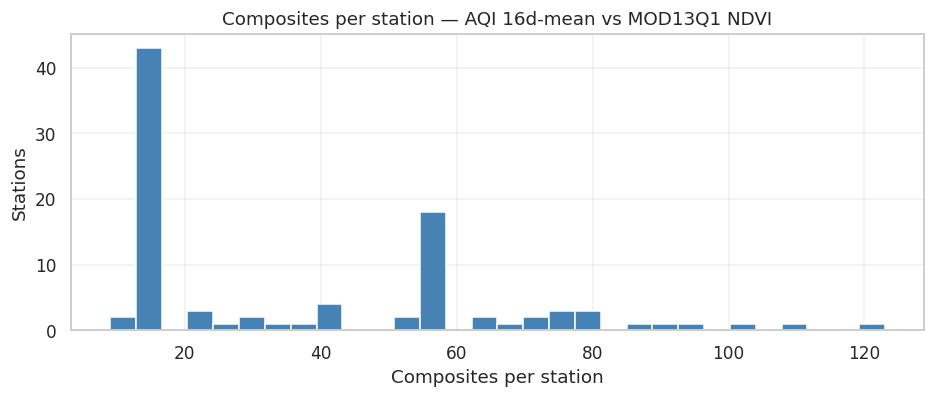

min/median/max composites per station: 9 / 23 / 123


,N_composites
station,
Hà Nội: 556 Nguyễn Văn Cừ (KK),123
"Trà Vinh: xã Dân Thành, TX Duyên Hải (KK)",111
Phú Thọ: đường Hùng Vương - Tp Việt Trì (KK),103
Quảng Ninh: UBND TP Uông Bí (KK),95
Bắc Ninh: Khu liên cơ Thuận Thành - thị trấn Hồ (KK),89
Bắc Ninh: UBND xã Cao Đức - Gia Bình (KK),85
"Trà Vinh: xã Đông Hải, huyện Duyên Hải (KK)",81
Quảng Ninh: Km11 - Minh Thành (KK),80
Đà Nẵng: 41 đường Lê Duẩn (KK),78


In [5]:
per_st = pairs.groupby('station').size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(per_st.values, bins=30, color='steelblue', edgecolor='white')
ax.set_xlabel('Composites per station'); ax.set_ylabel('Stations')
ax.set_title('Composites per station — AQI 16d-mean vs MOD13Q1 NDVI')
ax.grid(alpha=0.3)
save_fig('01_composites_per_station'); plt.show()
print(f'min/median/max composites per station: '
      f'{per_st.min()} / {int(per_st.median())} / {per_st.max()}')
per_st.head(10).to_frame('N_composites')

## 4. Network-wide scatter — one panel per NDVI variant

Both axes are at the same 16-day temporal scale, so points are independent samples (modulo station-level autocorrelation across consecutive composites).

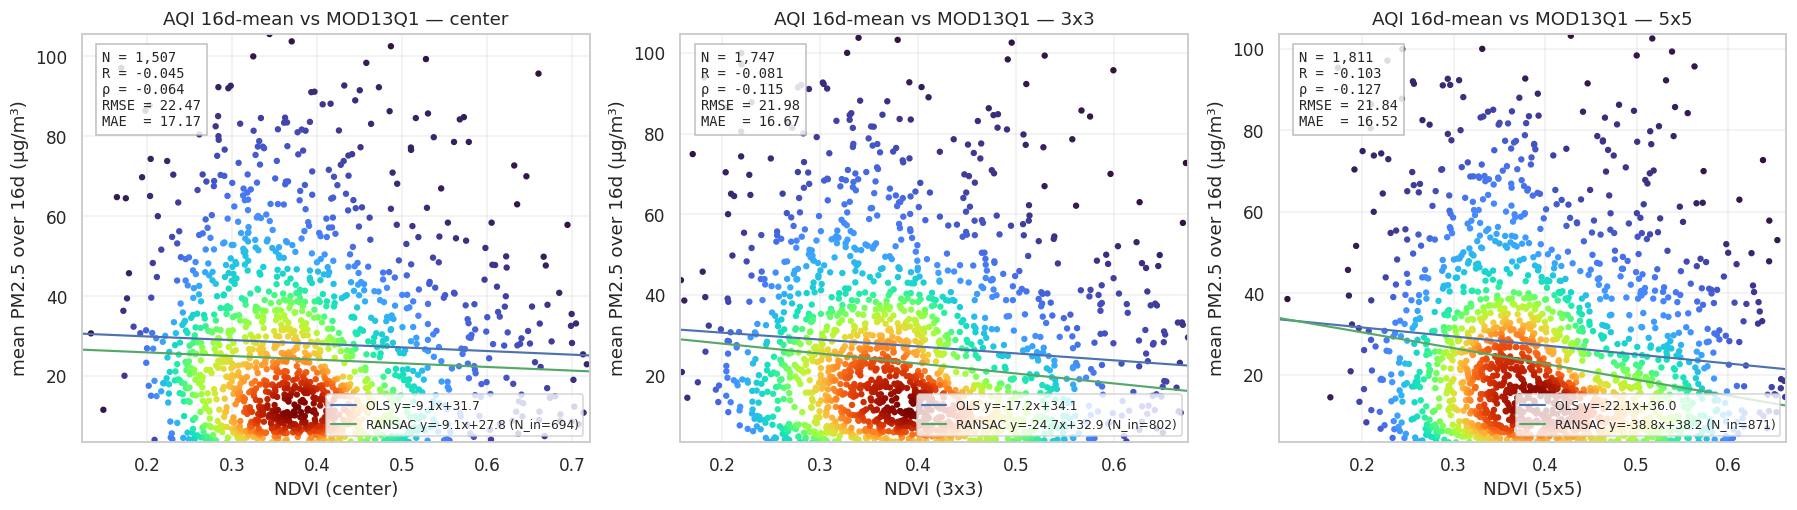

,N,R,R_spearman,RMSE,MAE,slope,intercept,slope_r,intercept_r,N_in
variant,,,,,,,,,,
center,1507,-0.045,-0.064,22.466,17.167,-9.124,31.749,-9.112,27.752,694
3x3,1747,-0.081,-0.115,21.985,16.671,-17.176,34.069,-24.715,32.859,802
5x5,1811,-0.103,-0.127,21.841,16.524,-22.094,36.049,-38.803,38.195,871


In [6]:
n_win = len(NDVI_WINDOWS)
fig, axes = plt.subplots(1, n_win, figsize=(5.5*n_win, 4.8), squeeze=False)
axes_flat = axes.ravel()
all_metrics = []
for ax, (label, col) in zip(axes_flat, NDVI_WINDOWS):
    sub = pairs[[col, 'pm25']].dropna()
    m = plot_scatter(ax, sub[col].values, sub['pm25'].values,
                     xlabel=f'NDVI ({label})',
                     title=f'AQI 16d-mean vs MOD13Q1 — {label}')
    m['variant'] = label
    all_metrics.append(m)
fig.tight_layout()
save_fig('02_network_scatter'); plt.show()
metrics_df = pd.DataFrame(all_metrics).set_index('variant')
metrics_df.round(3)

## 5. ⭐ Winner — which NDVI variant to use as the model feature

Ranks the three variants by `|Pearson R|`. Cross-check against Spearman ρ (rank correlation, robust to outliers) and RMSE / MAE before locking in.

Rule of thumb:
  - If 3×3 / 5×5 beat `center` by a meaningful margin → smoothed variant wins (NDVI is noisy at the pixel scale, station may sit on a mixed pixel).
  - If all three are within ≈0.01 of R → just pick the simplest (`center`) or the one with the cleanest valid-fraction distribution.

In [7]:
summary = metrics_df[['N', 'R', 'R_spearman', 'RMSE', 'MAE',
                       'slope', 'intercept', 'slope_r', 'intercept_r']].copy()
summary['|R|']  = summary['R'].abs()
summary['|ρ|']  = summary['R_spearman'].abs()
summary = summary.sort_values('|R|', ascending=False)

winner_R   = summary.index[0]
winner_rho = summary['|ρ|'].idxmax()
winner_mae = summary['MAE'].idxmin()
print(f'best by |Pearson R|   : {winner_R!r}  '
      f"(R={summary.loc[winner_R, 'R']:+.4f})")
print(f'best by |Spearman ρ|  : {winner_rho!r}  '
      f"(ρ={summary.loc[winner_rho, 'R_spearman']:+.4f})")
print(f'best by MAE           : {winner_mae!r}  '
      f"(MAE={summary.loc[winner_mae, 'MAE']:.3f})")

HEADLINE_LABEL = winner_R
HEADLINE_COL   = dict(NDVI_WINDOWS)[HEADLINE_LABEL]
print(f'\n→ headline variant for downstream panels: {HEADLINE_LABEL!r} ({HEADLINE_COL})')

(summary
    .drop(columns=['|R|', '|ρ|'])
    .round({'R': 4, 'R_spearman': 4, 'RMSE': 2, 'MAE': 2,
            'slope': 2, 'intercept': 2, 'slope_r': 2, 'intercept_r': 2}))

best by |Pearson R|   : '5x5'  (R=-0.1027)
best by |Spearman ρ|  : '5x5'  (ρ=-0.1272)
best by MAE           : '5x5'  (MAE=16.524)

→ headline variant for downstream panels: '5x5' (NDVI_5x5_mean)


,N,R,R_spearman,RMSE,MAE,slope,intercept,slope_r,intercept_r
variant,,,,,,,,,
5x5,1811,-0.1027,-0.1272,21.84,16.52,-22.09,36.05,-38.80,38.20
3x3,1747,-0.0812,-0.1151,21.98,16.67,-17.18,34.07,-24.71,32.86
center,1507,-0.0448,-0.0637,22.47,17.17,-9.12,31.75,-9.11,27.75


### 5.a Per-station R — is the winner consistent across stations?
Network-wide R can be dominated by a few stations with long histories. The median per-station R is the robust ranking. If §5 and §5.a disagree, trust §5.a.

Median per-station Pearson R:
R_5x5      -0.180
R_center   -0.148
R_3x3      -0.121

→ median per-station winner: '5x5'


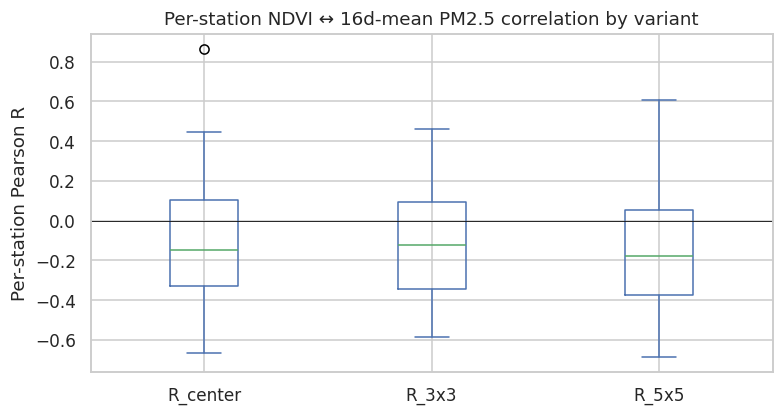

,N,R_center,R_3x3,R_5x5
station,,,,
"Bình Dương: số 593 Đại lộ Bình Dương, P. Hiệp Thành (KK)",55,-0.154,-0.160,-0.177
Bình Định: Khuôn viên Cây xanh gần cầu chui đường Hoa Lư - TP. Quy Nhơn (KK),56,-0.274,0.064,0.016
Bình Định: huyện Tuy Phước (KK),26,NaN,NaN,NaN
Bắc Giang: Thôn Vĩnh An - xã Song Mai - TP. Bắc Giang (KK),14,NaN,NaN,NaN
Bắc Ninh: KCN Tiên Sơn (Trạm cấp nước sạch KCN) - Từ Sơn (KK),29,NaN,NaN,-0.477
Bắc Ninh: KCN Yên Phong (gần trạm cấp nước sạch) (KK),22,0.070,-0.116,-0.333
Bắc Ninh: Khu liên cơ Thuận Thành - thị trấn Hồ (KK),89,-0.267,-0.247,-0.192
Bắc Ninh: TT Quan trắc - phường Suối Hoa - TP Bắc Ninh (KK),63,-0.148,-0.093,-0.149
"Bắc Ninh: UBND huyện Quế Võ, TT Phố Mới (KK)",55,-0.117,-0.221,-0.317


In [8]:
rows = []
for st, g in pairs.groupby('station'):
    rec = dict(station=st, N=len(g))
    for label, col in NDVI_WINDOWS:
        sub = g[[col, 'pm25']].dropna()
        if len(sub) >= 10 and sub[col].nunique() > 2:
            r, _ = stats.pearsonr(sub[col], sub['pm25'])
        else:
            r = np.nan
        rec[f'R_{label}'] = r
    rows.append(rec)
per_st_R = pd.DataFrame(rows).set_index('station')

med = per_st_R.filter(like='R_').median().sort_values(key=lambda s: s.abs(), ascending=False)
print('Median per-station Pearson R:')
print(med.round(3).to_string())
median_winner = med.abs().idxmax().replace('R_', '')
print(f"\n→ median per-station winner: {median_winner!r}")

fig, ax = plt.subplots(figsize=(8, 4))
per_st_R.filter(like='R_').plot.box(ax=ax, grid=True)
ax.axhline(0, color='k', lw=0.6)
ax.set_ylabel('Per-station Pearson R')
ax.set_title('Per-station NDVI ↔ 16d-mean PM2.5 correlation by variant')
save_fig('05a_per_station_R'); plt.show()
per_st_R.head(10).round(3)

## 6. Per-region scatter — headline variant only

Faceted by Vietnamese region. Reveals whether the NDVI ↔ PM2.5 relationship is universal or carried by one region (e.g. RRD urban vs CH vegetated highlands).

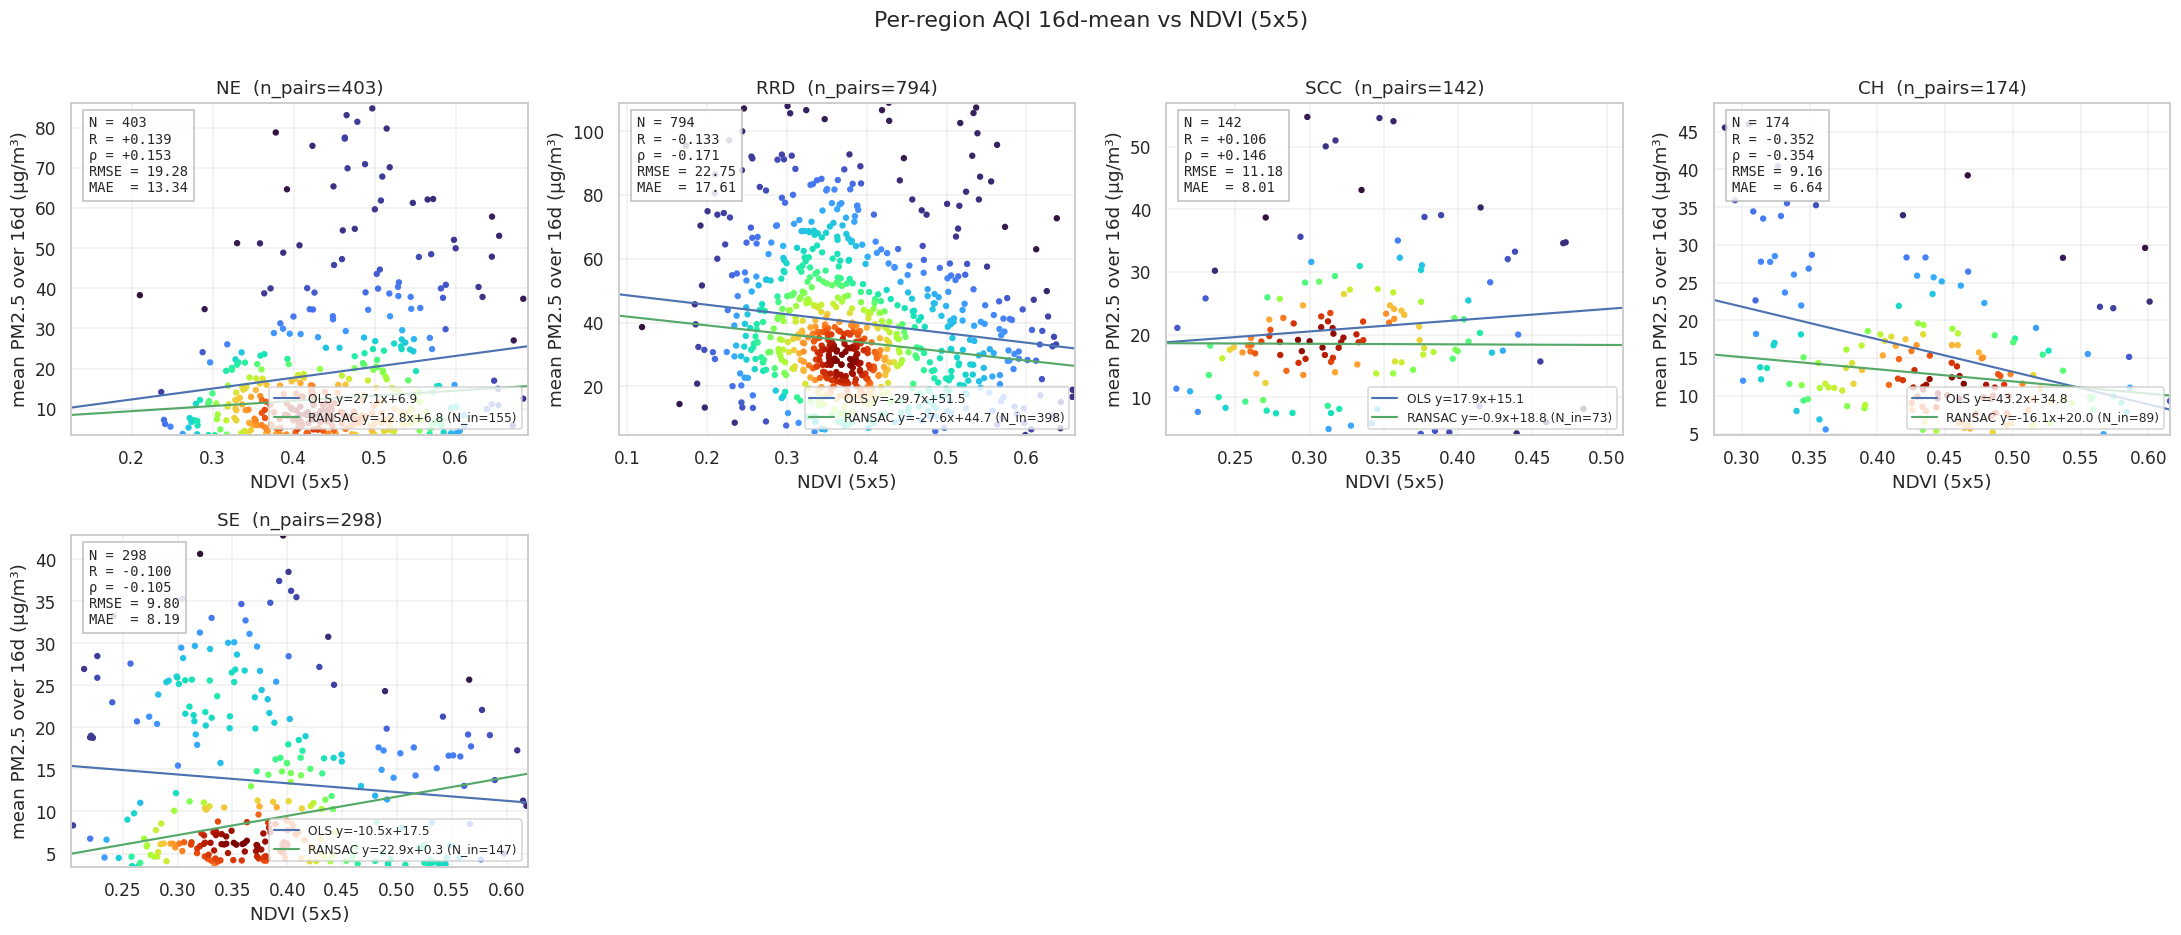

,N,R,R_spearman,RMSE,MAE,slope,intercept,slope_r,intercept_r,N_in
region,,,,,,,,,,
NE,403,0.139,0.153,19.281,13.344,27.086,6.894,12.753,6.846,155
RRD,794,-0.133,-0.171,22.747,17.608,-29.688,51.530,-27.575,44.655,398
SCC,142,0.106,0.146,11.176,8.014,17.947,15.105,-0.941,18.801,73
CH,174,-0.352,-0.354,9.163,6.643,-43.161,34.756,-16.103,19.957,89
SE,298,-0.100,-0.105,9.805,8.186,-10.463,17.546,22.884,0.327,147


In [9]:
REGIONS = ['NW','NE','RRD','NCC','SCC','CH','SE']
regions_present = [r for r in REGIONS if r in pairs['region'].unique()]
ncols = 4; nrows = -(-len(regions_present) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0*ncols, 4.2*nrows), squeeze=False)
axes_flat = axes.ravel()
region_metrics = []
for ax, region in zip(axes_flat, regions_present):
    sub = pairs[pairs['region']==region][[HEADLINE_COL, 'pm25']].dropna()
    if sub.empty:
        ax.set_axis_off(); continue
    m = plot_scatter(ax, sub[HEADLINE_COL].values, sub['pm25'].values,
                     xlabel=f'NDVI ({HEADLINE_LABEL})',
                     title=f'{region}  (n_pairs={len(sub):,})')
    m['region'] = region
    region_metrics.append(m)
for ax in axes_flat[len(regions_present):]: ax.set_axis_off()
fig.suptitle(f'Per-region AQI 16d-mean vs NDVI ({HEADLINE_LABEL})', y=1.01)
fig.tight_layout()
save_fig('06_per_region_scatter'); plt.show()
pd.DataFrame(region_metrics).set_index('region').round(3)

## 7. R within NDVI bins — headline variant

Stratify NDVI into vegetation-class bins; report mean PM2.5 and R within each. A clean monotone trend (higher NDVI → lower mean PM2.5) confirms the global sign of the relationship; a flat curve means NDVI alone carries little signal.

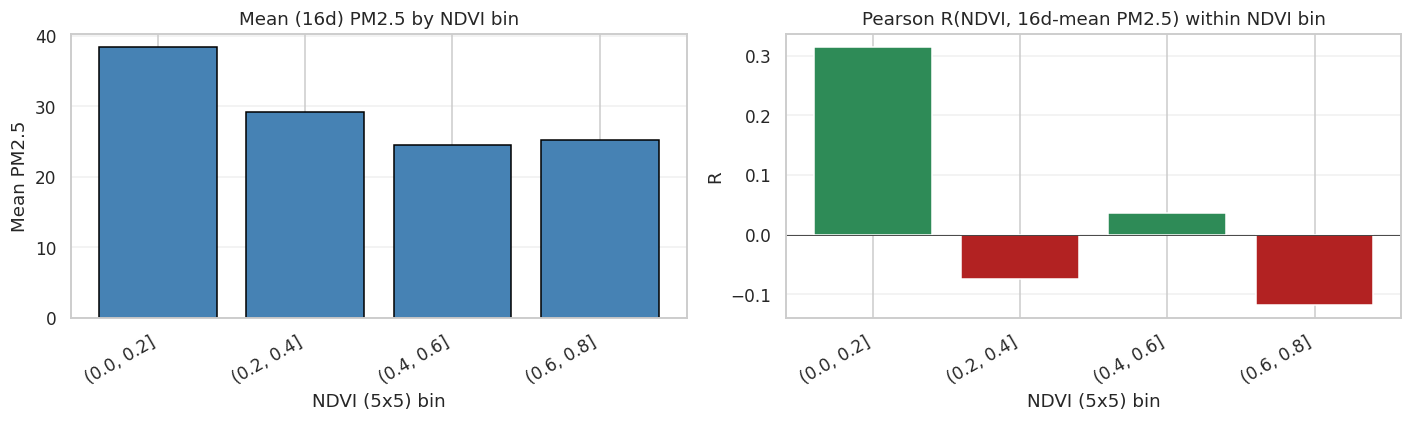

,ndvi_bin,N,mean_PM,median_PM,R
0,"(0.0, 0.2]",12,38.330954,35.487827,0.315
1,"(0.2, 0.4]",958,29.198384,23.919160,-0.075
2,"(0.4, 0.6]",774,24.502189,17.419241,0.036
3,"(0.6, 0.8]",66,25.243247,18.494635,-0.118


In [10]:
sub = pairs[[HEADLINE_COL, 'pm25']].dropna()
sub['ndvi_bin'] = pd.cut(sub[HEADLINE_COL],
                         bins=[-0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
rows = []
for b, g in sub.groupby('ndvi_bin', observed=True):
    if len(g) < 5: continue
    if g[HEADLINE_COL].nunique() > 1:
        r, _ = stats.pearsonr(g[HEADLINE_COL], g['pm25'])
    else:
        r = np.nan
    rows.append(dict(ndvi_bin=str(b), N=len(g),
                     mean_PM=g['pm25'].mean(),
                     median_PM=g['pm25'].median(),
                     R=None if np.isnan(r) else round(r, 3)))
bin_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(bin_df['ndvi_bin'].astype(str), bin_df['mean_PM'],
            color='steelblue', edgecolor='black')
axes[0].set_title('Mean (16d) PM2.5 by NDVI bin')
axes[0].set_xlabel(f'NDVI ({HEADLINE_LABEL}) bin'); axes[0].set_ylabel('Mean PM2.5')
axes[0].grid(alpha=0.3, axis='y')
plt.setp(axes[0].get_xticklabels(), rotation=30, ha='right')

rs = bin_df['R'].fillna(0).astype(float)
axes[1].bar(bin_df['ndvi_bin'].astype(str), rs,
            color=['firebrick' if r < 0 else 'seagreen' for r in rs])
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_title('Pearson R(NDVI, 16d-mean PM2.5) within NDVI bin')
axes[1].set_xlabel(f'NDVI ({HEADLINE_LABEL}) bin'); axes[1].set_ylabel('R')
axes[1].grid(alpha=0.3, axis='y')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')
save_fig('07_bin_analysis'); plt.tight_layout(); plt.show()
bin_df

## Notes

- **No pseudoreplication**: PM2.5 is aggregated to the same 16-day window as NDVI, so each pair is one independent (station, composite) observation. N is smaller (~10⁴ instead of 10⁶) but every row carries new information.
- **`MIN_HOURS_PER_COMPOSITE`** (default 24): composite is dropped if the station has fewer than 24 hourly PM2.5 samples in those 16 days. Raise it for stricter QA (e.g. 96 = 4 full days) or lower it for sparser stations.
- **Residual autocorrelation**: even at 16-day scale, consecutive composites of the same station are correlated (same site, seasonal trend). That's why §5 / §5.a both matter — §5.a averages out site effects.
- **Pick rule**: if §5 and §5.a agree → use that variant. If they disagree → trust §5.a (per-station median is robust to network-size imbalance).
- Source data: `MODIS_MOD13Q1/stations/<station>.csv` and `AQI/process/<station>.csv`. Figures saved to `pm25_map/ndvi/figures/`.